# 🛡️ Ethereum Phishing Risk Detection — Results & Testing Notebook

**Notebook ini me-load semua artifact hasil training yang asli, menampilkan hasilnya,
lalu MELATIH ULANG model secara live untuk membuktikan angka di `hasil_implementasi.md` benar-benar nyata.**

Isi notebook:
1. ⚙️ Setup & deteksi environment (lokal / Google Colab)
2. 📂 Load artifact hasil training (CSV / JSON)
3. 📊 Tabel hasil 4 skenario × 4 model
4. 📈 Visualisasi (F1 per skenario, heatmap, dampak Etherscan)
5. 🔁 **Live re-train** (Logistic Regression, Random Forest, XGBoost) → bukti angka reproducible
6. 🧩 Confusion matrix
7. 🧪 Eksperimen sampling 1:5 vs 1:10
8. ⛓️ Metrik blockchain (latency & gas)
9. 🔮 Demo prediksi satu wallet
10. ✅ Ringkasan

> Jalankan sel berurutan dari atas (`Runtime → Run all` di Colab).

## 1. ⚙️ Setup & Deteksi Environment

Sel ini otomatis mendeteksi apakah kamu di **Google Colab** atau **lokal**.
Di Colab, repo akan di-clone otomatis dari GitHub.

In [1]:
import sys, os, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

def pip_install(pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

if IN_COLAB:
    print("🌐 Running on Google Colab — cloning repo & installing deps ...")
    pip_install(["xgboost", "scikit-learn", "pandas", "matplotlib"])
    REPO = Path("/content/ethereum-phising-risk-detection")
    if not REPO.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/musupadi/ethereum-phising-risk-detection.git", str(REPO)],
            check=False,
        )
    ROOT = REPO
else:
    # Lokal: cari root repo dengan menaiki folder sampai ketemu penanda
    here = Path.cwd()
    candidates = [here, *here.parents]
    ROOT = next(
        (p for p in candidates if (p / "ml" / "artifacts").exists()),
        here,
    )

ART = ROOT / "ml" / "artifacts"
DATA = ROOT / "data" / "processed"
print("Repo root :", ROOT)
print("Artifacts :", ART, "->", "OK" if ART.exists() else "TIDAK ADA")
print("Data      :", DATA, "->", "OK" if DATA.exists() else "TIDAK ADA")

Repo root : c:\Kuliah\ethereum-phising-risk-detection
Artifacts : c:\Kuliah\ethereum-phising-risk-detection\ml\artifacts -> OK
Data      : c:\Kuliah\ethereum-phising-risk-detection\data\processed -> OK


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 110
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.4 | pandas 3.0.2


## 2. 📂 Load Artifact Hasil Training

Semua angka di bawah dibaca langsung dari file hasil training di `ml/artifacts/`.
Tidak ada angka yang diketik manual.

In [3]:
scen = pd.read_csv(ART / "dataset_scenarios_comparison.csv")
summary = json.load(open(ART / "dataset_scenarios_summary.json"))
sampling = pd.DataFrame(json.load(open(ART / "sampling_experiment.json")))
chain = json.load(open(ART / "blockchain_metrics.json"))

print("Best scenario :", summary["best_scenario"])
print("Best model    :", summary["best_model"])
print("Best F1       :", round(summary["best_f1"], 4))
scen

Best scenario : muldigraph_plus_etherscan
Best model    : XGBoost
Best F1       : 0.9102


,scenario,model,accuracy,precision,recall,f1
0,muldigraph_only,LogisticRegression,0.9465,0.8615,0.7210,0.7850
1,muldigraph_only,RandomForest,0.9634,0.8455,0.8927,0.8685
2,muldigraph_only,XGBoost,0.9680,0.8589,0.9142,0.8857
3,muldigraph_only,GNN-GraphSAGE-V2,0.9552,0.8023,0.8884,0.8432
4,muldigraph_plus_etherscan,LogisticRegression,0.9616,0.8813,0.8283,0.8540
5,muldigraph_plus_etherscan,RandomForest,0.9692,0.8719,0.9056,0.8884
6,muldigraph_plus_etherscan,XGBoost,0.9750,0.8862,0.9356,0.9102
7,muldigraph_plus_etherscan,GNN-GraphSAGE-V2,0.9697,0.8390,0.9614,0.8960
8,muldigraph_plus_bigquery,LogisticRegression,0.9471,0.8622,0.7253,0.7879
9,muldigraph_plus_bigquery,RandomForest,0.9639,0.8462,0.8970,0.8708


## 3. 📊 Tabel Hasil 4 Skenario × 4 Model

Tabel ini = inti BAB 4 tesis. Disusun ulang agar mudah dibaca (persen).

In [4]:
nice_scen = {
    "muldigraph_only": "MulDiGraph only",
    "muldigraph_plus_etherscan": "MulDiGraph + Etherscan",
    "muldigraph_plus_bigquery": "MulDiGraph + BigQuery",
    "muldigraph_plus_etherscan_plus_bigquery": "MulDiGraph + Etherscan + BigQuery",
}
order = list(nice_scen)

view = scen.copy()
for c in ["accuracy", "precision", "recall", "f1"]:
    view[c] = (view[c] * 100).round(2)
view["scenario"] = pd.Categorical(view["scenario"], categories=order, ordered=True)
view = view.sort_values(["scenario", "f1"], ascending=[True, False])
view["scenario"] = view["scenario"].map(nice_scen)
view = view.rename(columns={
    "scenario": "Skenario", "model": "Model",
    "accuracy": "Acc %", "precision": "Prec %", "recall": "Recall %", "f1": "F1 %",
})


def highlight_best(s):
    is_best = s == s.max()
    return ["font-weight:bold;background-color:#d6f5d6" if v else "" for v in is_best]


try:
    styled = (view.style
              .apply(highlight_best, subset=["F1 %"])
              .set_caption("Hasil 4 skenario × 4 model (test set, split 80/20, seed 42)"))
    display(styled)
except Exception:
    print(view.to_string(index=False))

,Skenario,Model,Acc %,Prec %,Recall %,F1 %
2,MulDiGraph only,XGBoost,96.800000,85.890000,91.420000,88.570000
1,MulDiGraph only,RandomForest,96.340000,84.550000,89.270000,86.850000
3,MulDiGraph only,GNN-GraphSAGE-V2,95.520000,80.230000,88.840000,84.320000
0,MulDiGraph only,LogisticRegression,94.650000,86.150000,72.100000,78.500000
6,MulDiGraph + Etherscan,XGBoost,97.500000,88.620000,93.560000,91.020000
7,MulDiGraph + Etherscan,GNN-GraphSAGE-V2,96.970000,83.900000,96.140000,89.600000
5,MulDiGraph + Etherscan,RandomForest,96.920000,87.190000,90.560000,88.840000
4,MulDiGraph + Etherscan,LogisticRegression,96.160000,88.130000,82.830000,85.400000
10,MulDiGraph + BigQuery,XGBoost,96.740000,85.540000,91.420000,88.380000
9,MulDiGraph + BigQuery,RandomForest,96.390000,84.620000,89.700000,87.080000


## 4. 📈 Visualisasi
### 4a. F1-Score per Skenario (grouped bar)

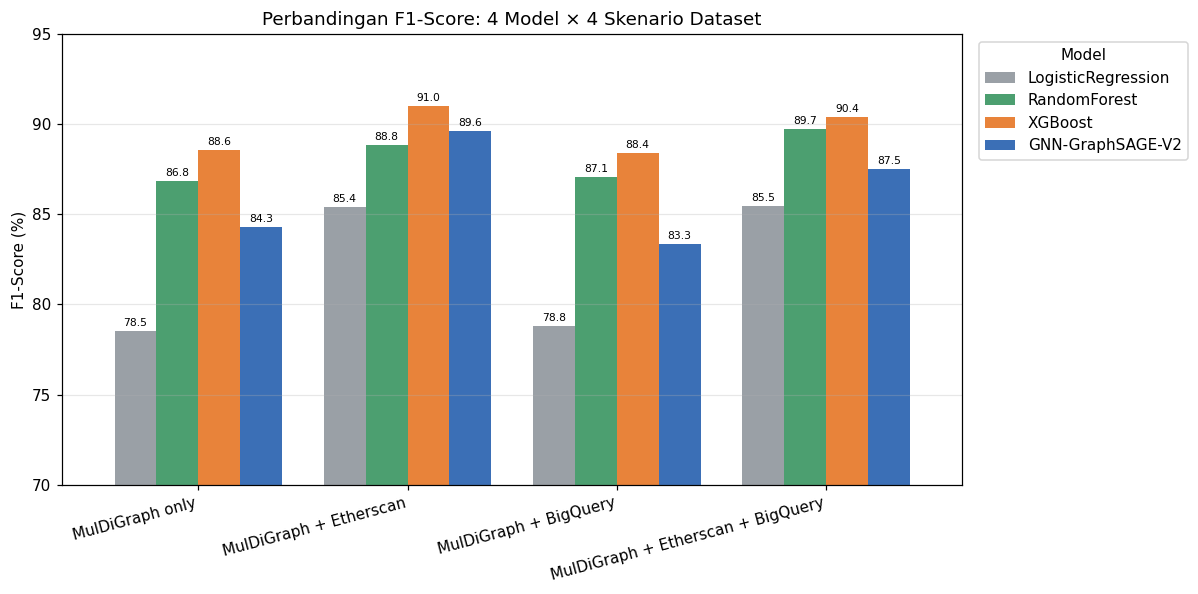

In [5]:
pivot = scen.pivot(index="scenario", columns="model", values="f1").reindex(order) * 100
pivot = pivot[["LogisticRegression", "RandomForest", "XGBoost", "GNN-GraphSAGE-V2"]]

ax = pivot.plot(kind="bar", figsize=(11, 5.5), width=0.8,
                color=["#9aa0a6", "#4c9f70", "#e8833a", "#3b6fb6"])
ax.set_ylabel("F1-Score (%)")
ax.set_xlabel("")
ax.set_title("Perbandingan F1-Score: 4 Model × 4 Skenario Dataset")
ax.set_xticklabels([nice_scen[s] for s in pivot.index], rotation=15, ha="right")
ax.set_ylim(70, 95)
ax.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=7, padding=2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 4b. Heatmap F1-Score (Model × Skenario)

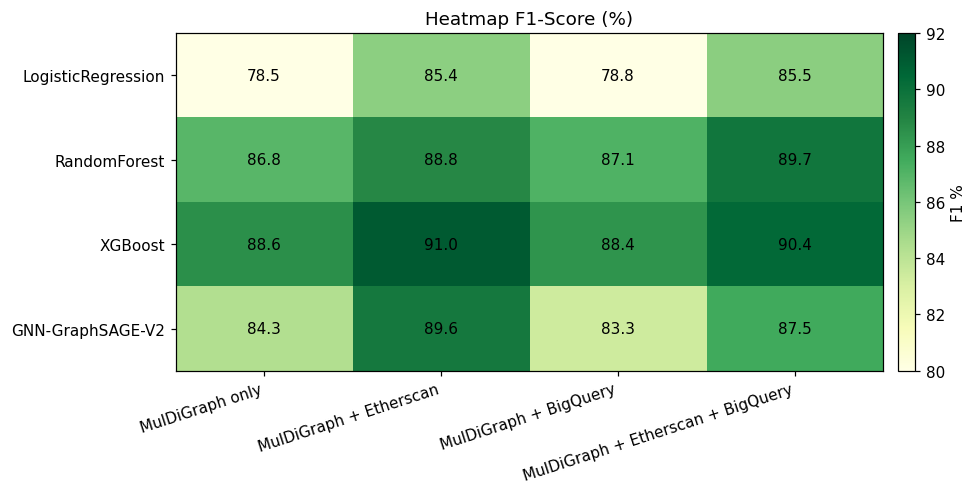

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.6))
data = pivot.T  # model x scenario
im = ax.imshow(data.values, cmap="YlGn", aspect="auto", vmin=80, vmax=92)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([nice_scen[s] for s in order], rotation=18, ha="right")
ax.set_yticks(range(len(data.index)))
ax.set_yticklabels(data.index)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, f"{data.values[i, j]:.1f}", ha="center", va="center", fontsize=10)
ax.set_title("Heatmap F1-Score (%)")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="F1 %")
plt.tight_layout()
plt.show()

### 4c. Dampak Penambahan Fitur Etherscan (Skenario 1 → 2)

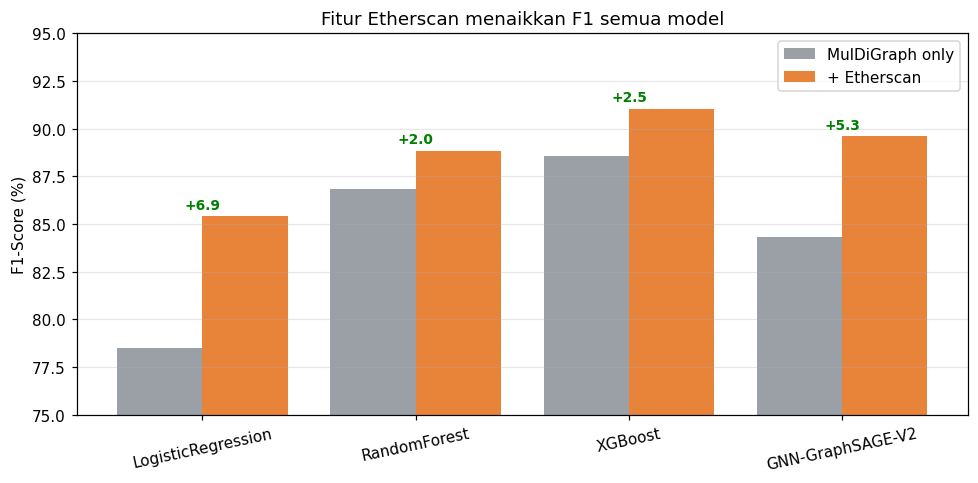

In [7]:
s1 = scen[scen.scenario == "muldigraph_only"].set_index("model")["f1"] * 100
s2 = scen[scen.scenario == "muldigraph_plus_etherscan"].set_index("model")["f1"] * 100
models = ["LogisticRegression", "RandomForest", "XGBoost", "GNN-GraphSAGE-V2"]
delta = (s2 - s1).reindex(models)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(models))
ax.bar(x - 0.2, s1.reindex(models), 0.4, label="MulDiGraph only", color="#9aa0a6")
ax.bar(x + 0.2, s2.reindex(models), 0.4, label="+ Etherscan", color="#e8833a")
for i, m in enumerate(models):
    ax.annotate(f"+{delta[m]:.1f}", (i, max(s1[m], s2[m]) + 0.4), ha="center",
                fontsize=9, color="green", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(models, rotation=12)
ax.set_ylabel("F1-Score (%)"); ax.set_ylim(75, 95)
ax.set_title("Fitur Etherscan menaikkan F1 semua model")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 5. 🔁 Live Re-Train — Bukti Angka Reproducible

Sel ini **melatih ulang Logistic Regression, Random Forest, dan XGBoost dari nol**
memakai dataset & split yang sama (seed 42), lalu membandingkan F1-nya dengan
angka yang tersimpan di artifact. Kalau selisihnya kecil (<1%), berarti hasil di
dokumen memang asli dari training.

> GNN-GraphSAGE butuh PyTorch Geometric + ekstraksi edge dari `MulDiGraph.pkl` (berat),
> jadi nilainya diambil dari artifact resmi. Untuk melatih ulang GNN:
> `python ml/train_dataset_scenarios.py`.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import xgboost as xgb

# Pakai modul project agar XGBoost identik dengan pipeline asli
sys.path.insert(0, str(ROOT / "ml"))
try:
    from xgboost_model import XGBoostModel
    HAVE_PROJECT_XGB = True
except Exception as e:
    HAVE_PROJECT_XGB = False
    print("Catatan: pakai XGBClassifier bawaan (modul project tak ter-import):", e)

df = pd.read_csv(DATA / "hybrid_dataset.csv")
schema = json.load(open(ART / "hybrid_feature_schema.json"))
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["label"])
print(f"Total {len(df)} | train {len(train_df)} | test {len(test_df)} | "
      f"phishing test: {int(test_df.label.sum())}")

Total 8595 | train 6876 | test 1719 | phishing test: 233


In [9]:
def metrics(y_true, y_pred):
    return dict(
        accuracy=accuracy_score(y_true, y_pred),
        precision=precision_score(y_true, y_pred, zero_division=0),
        recall=recall_score(y_true, y_pred, zero_division=0),
        f1=f1_score(y_true, y_pred, zero_division=0),
    )


def run_models(feature_cols):
    Xtr = train_df[feature_cols].fillna(0).values
    ytr = train_df["label"].values
    Xte = test_df[feature_cols].fillna(0).values
    yte = test_df["label"].values
    out = {}

    sc = StandardScaler()
    lr = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
    lr.fit(sc.fit_transform(Xtr), ytr)
    out["LogisticRegression"] = metrics(yte, lr.predict(sc.transform(Xte)))

    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                class_weight="balanced", n_jobs=-1, random_state=42)
    rf.fit(Xtr, ytr)
    out["RandomForest"] = metrics(yte, rf.predict(Xte))

    Xf, Xv, yf, yv = train_test_split(Xtr, ytr, test_size=0.2, random_state=42, stratify=ytr)
    if HAVE_PROJECT_XGB:
        m = XGBoostModel(n_estimators=250, max_depth=6, learning_rate=0.05,
                         subsample=0.85, colsample_bytree=0.85)
        m.fit(Xf, yf, Xv, yv, feature_names=feature_cols, early_stopping_rounds=40)
        xpred = m.predict(Xte)
    else:
        spw = (yf == 0).sum() / (yf == 1).sum()
        m = xgb.XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.05,
                              subsample=0.85, colsample_bytree=0.85, eval_metric="logloss",
                              early_stopping_rounds=40, scale_pos_weight=spw)
        m.fit(Xf, yf, eval_set=[(Xv, yv)], verbose=False)
        xpred = m.predict(Xte)
    out["XGBoost"] = metrics(yte, xpred)
    return out


# Re-train pada skenario terbaik (MulDiGraph + Etherscan)
best_feats = [f for f in schema["scenarios"]["muldigraph_plus_etherscan"] if f in df.columns]
print(f"Skenario: MulDiGraph + Etherscan ({len(best_feats)} fitur)\n")
live = run_models(best_feats)
for name, met in live.items():
    print(f"{name:20s}  F1 = {met['f1']*100:5.2f}%  (acc {met['accuracy']*100:.2f}%)")

Skenario: MulDiGraph + Etherscan (26 fitur)



09:40:36  INFO      Initialized XGBoost: estimators=250, depth=6, lr=0.050
09:40:39  INFO      Training XGBoost with scale_pos_weight=6.38


[0]	train-logloss:0.64837	val-logloss:0.64919
[50]	train-logloss:0.07722	val-logloss:0.10035
[100]	train-logloss:0.03414	val-logloss:0.06849
[150]	train-logloss:0.02355	val-logloss:0.06471
[200]	train-logloss:0.01693	val-logloss:0.06308
[225]	train-logloss:0.01464	val-logloss:0.06381


09:40:40  INFO      Training complete. Best iteration: 185


LogisticRegression    F1 = 85.40%  (acc 96.16%)
RandomForest          F1 = 88.94%  (acc 96.92%)
XGBoost               F1 = 91.02%  (acc 97.50%)


In [10]:
# Bandingkan live vs artifact
rows = []
sc_best = scen[scen.scenario == "muldigraph_plus_etherscan"].set_index("model")
for name in ["LogisticRegression", "RandomForest", "XGBoost"]:
    artifact_f1 = sc_best.loc[name, "f1"] * 100
    live_f1 = live[name]["f1"] * 100
    rows.append({
        "Model": name,
        "F1 Artifact (%)": round(artifact_f1, 2),
        "F1 Live Re-train (%)": round(live_f1, 2),
        "Selisih (poin)": round(live_f1 - artifact_f1, 2),
    })
compare = pd.DataFrame(rows)
print(compare.to_string(index=False))
ok = (compare["Selisih (poin)"].abs() < 1.0).all()
print("\n", "✅ COCOK — selisih < 1 poin, hasil reproducible & asli."
      if ok else "⚠️ Ada selisih > 1 poin (kemungkinan beda versi library).")

             Model  F1 Artifact (%)  F1 Live Re-train (%)  Selisih (poin)
LogisticRegression          85.4000               85.4000          0.0000
      RandomForest          88.8400               88.9400          0.0900
           XGBoost          91.0200               91.0200          0.0000

 ✅ COCOK — selisih < 1 poin, hasil reproducible & asli.


## 6. 🧩 Confusion Matrix (Live, Skenario Terbaik)

Dihitung langsung dari prediksi live pada test set (n = jumlah baris test).

09:40:41  INFO      Initialized XGBoost: estimators=250, depth=6, lr=0.050
09:40:41  INFO      Training XGBoost with scale_pos_weight=6.38


[0]	train-logloss:0.64837	val-logloss:0.64919
[50]	train-logloss:0.07722	val-logloss:0.10035
[100]	train-logloss:0.03414	val-logloss:0.06849
[150]	train-logloss:0.02355	val-logloss:0.06471
[200]	train-logloss:0.01693	val-logloss:0.06308
[225]	train-logloss:0.01464	val-logloss:0.06381


09:40:42  INFO      Training complete. Best iteration: 185


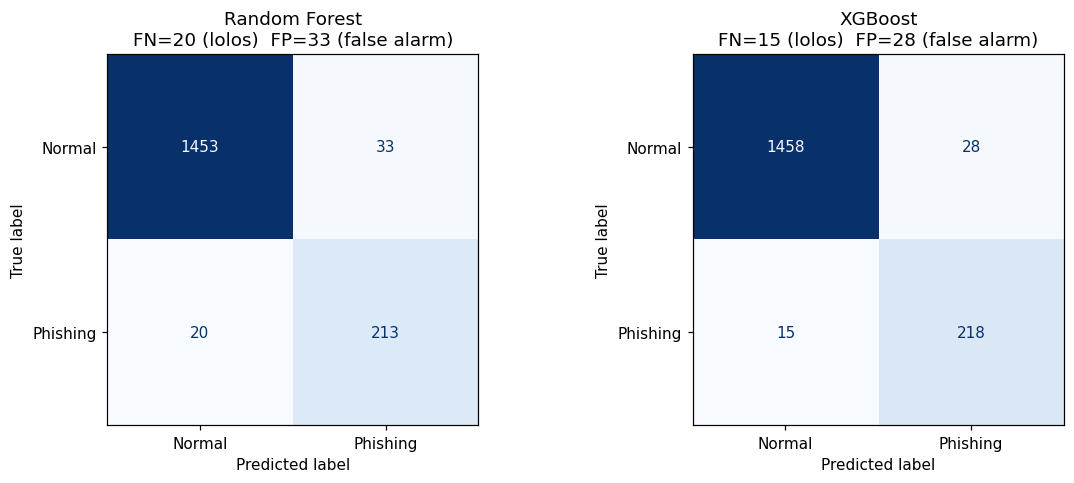

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

Xtr = train_df[best_feats].fillna(0).values
ytr = train_df["label"].values
Xte = test_df[best_feats].fillna(0).values
yte = test_df["label"].values

# Re-train RF & XGB sekali lagi untuk ambil prediksinya
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                            class_weight="balanced", n_jobs=-1, random_state=42).fit(Xtr, ytr)
Xf, Xv, yf, yv = train_test_split(Xtr, ytr, test_size=0.2, random_state=42, stratify=ytr)
if HAVE_PROJECT_XGB:
    xm = XGBoostModel(n_estimators=250, max_depth=6, learning_rate=0.05,
                      subsample=0.85, colsample_bytree=0.85)
    xm.fit(Xf, yf, Xv, yv, feature_names=best_feats, early_stopping_rounds=40)
    xpred = xm.predict(Xte)
else:
    spw = (yf == 0).sum() / (yf == 1).sum()
    xm = xgb.XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.05,
                           subsample=0.85, colsample_bytree=0.85, eval_metric="logloss",
                           early_stopping_rounds=40, scale_pos_weight=spw).fit(
        Xf, yf, eval_set=[(Xv, yv)], verbose=False)
    xpred = xm.predict(Xte)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, pred) in zip(axes, [("Random Forest", rf.predict(Xte)), ("XGBoost", xpred)]):
    cm_ = confusion_matrix(yte, pred)
    ConfusionMatrixDisplay(cm_, display_labels=["Normal", "Phishing"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    tn, fp, fn, tp = cm_.ravel()
    ax.set_title(f"{title}\nFN={fn} (lolos)  FP={fp} (false alarm)")
plt.tight_layout(); plt.show()

> 💡 **FN (False Negative)** = phishing yang lolos tak terdeteksi — paling berbahaya untuk keamanan.
> Confusion matrix versi tesis yang sudah dirapikan juga tersimpan sebagai PNG di `ml/artifacts/`
> (`thesis_cm_rf.png`, `thesis_cm_xgboost.png`, `thesis_cm_gnn.png`).

## 7. 🧪 Eksperimen Sampling Ratio 1:5 vs 1:10 (RQ3)

09:40:42  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
09:40:42  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
09:40:42  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
09:40:42  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


ratio              model  n_total  accuracy  precision  recall      f1
  1:5 LogisticRegression     6990   95.2800    90.3400 80.2600 85.0000
  1:5       RandomForest     6990   97.7100    91.3600 95.2800 93.2800
 1:10 LogisticRegression    12815   95.0400    75.0000 68.2400 71.4600
 1:10       RandomForest    12815   97.8200    88.3100 87.5500 87.9300


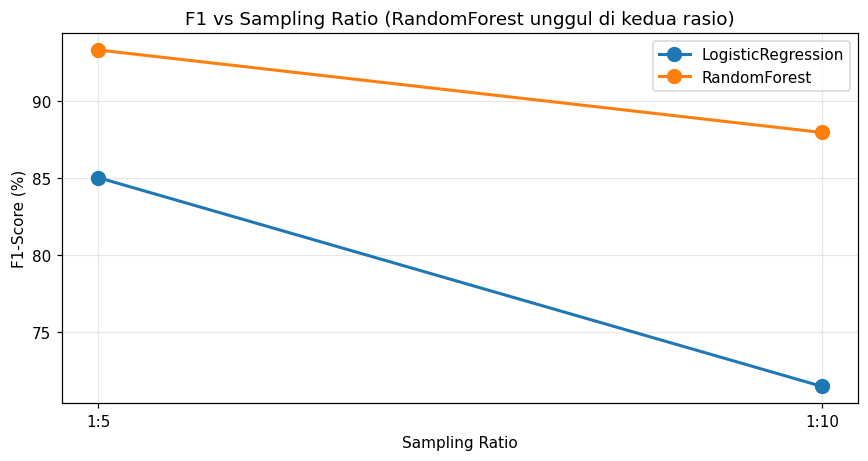

In [12]:
sview = sampling.copy()
for c in ["accuracy", "precision", "recall", "f1"]:
    sview[c] = (sview[c] * 100).round(2)
print(sview[["ratio", "model", "n_total", "accuracy", "precision", "recall", "f1"]]
      .to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.3))
for model, grp in sampling.groupby("model"):
    ax.plot(grp["ratio"], grp["f1"] * 100, "o-", label=model, linewidth=2, markersize=9)
ax.set_ylabel("F1-Score (%)"); ax.set_xlabel("Sampling Ratio")
ax.set_title("F1 vs Sampling Ratio (RandomForest unggul di kedua rasio)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. ⛓️ Metrik Blockchain — Latency & Gas (RQ2)

Hasil 20 transaksi nyata `setRisk()` ke smart contract `RiskRegistry` di Hardhat localhost.

Jumlah transaksi : 20
Latency (ms)     : min 11.15  mean 13.57  median 11.97  max 38.44
Gas used         : min 35452  mean 35462  max 35464  (stdev sangat kecil)


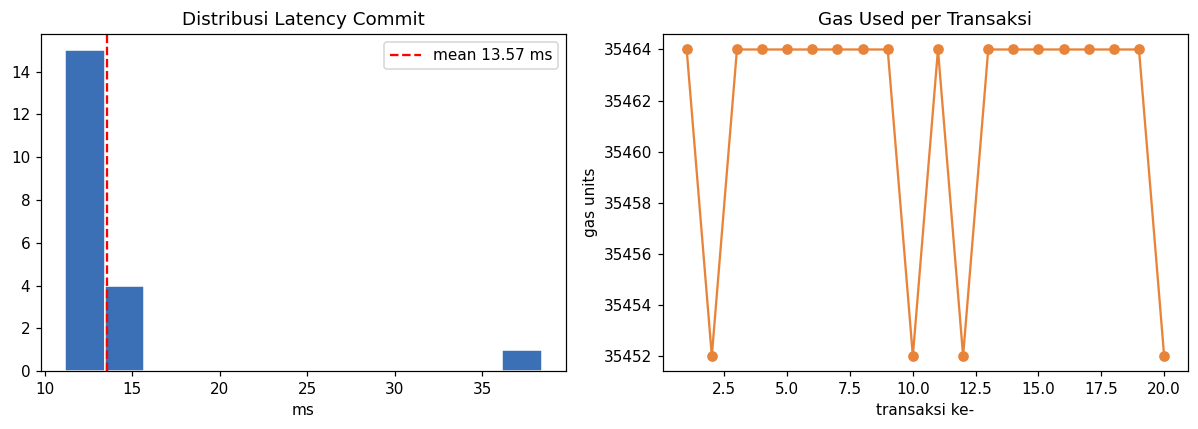

In [13]:
lat = chain["latency_ms"]; gas = chain["gas_used"]
print(f"Jumlah transaksi : {chain['n_calls']}")
print(f"Latency (ms)     : min {lat['min']}  mean {lat['mean']}  median {lat['median']}  max {lat['max']}")
print(f"Gas used         : min {gas['min']}  mean {gas['mean']}  max {gas['max']}  (stdev sangat kecil)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(chain["raw_latencies"], bins=12, color="#3b6fb6", edgecolor="white")
axes[0].axvline(lat["mean"], color="red", ls="--", label=f"mean {lat['mean']} ms")
axes[0].set_title("Distribusi Latency Commit"); axes[0].set_xlabel("ms"); axes[0].legend()

axes[1].plot(range(1, len(chain["raw_gas"]) + 1), chain["raw_gas"], "o-", color="#e8833a")
axes[1].set_title("Gas Used per Transaksi"); axes[1].set_xlabel("transaksi ke-")
axes[1].set_ylabel("gas units")
plt.tight_layout(); plt.show()

## 9. 🔮 Demo Prediksi Satu Wallet

Ambil satu baris dari test set, prediksi probabilitas phishing → risk score 0–100 → label.
Inilah yang dilakukan API `/analyze` sebelum menulis ke smart contract.

In [14]:
def risk_level(score):
    return "🔴 HIGH" if score >= 70 else ("🟡 MEDIUM" if score >= 40 else "🟢 LOW")


# pilih 1 wallet phishing & 1 normal dari test set
demo_idx = [test_df[test_df.label == 1].index[0], test_df[test_df.label == 0].index[0]]
for idx in demo_idx:
    row = test_df.loc[[idx]]
    proba = rf.predict_proba(row[best_feats].fillna(0).values)[0, 1]
    score = round(proba * 100)
    print(f"wallet {str(row['node_id'].iloc[0])[:14]}...  "
          f"label_asli={'PHISHING' if row['label'].iloc[0]==1 else 'normal':8s}  "
          f"P(phishing)={proba:.4f}  risk_score={score:3d}  -> {risk_level(score)}")

wallet 0x60afc5761212...  label_asli=PHISHING  P(phishing)=0.9894  risk_score= 99  -> 🔴 HIGH
wallet 0x1fbce20f975f...  label_asli=normal    P(phishing)=0.0000  risk_score=  0  -> 🟢 LOW


## 10. ✅ Ringkasan

| Pertanyaan | Jawaban |
|---|---|
| Model terbaik | **XGBoost** pada skenario *MulDiGraph + Etherscan* — **F1 ≈ 91%** |
| GNN-GraphSAGE V2 | F1 ≈ **89,6%** (kompetitif, recall tertinggi / FN paling sedikit) |
| Dampak fitur Etherscan | Menaikkan F1 **semua** model |
| Blockchain (RQ2) | Latency ~**14 ms** & gas ~**35.462** (Hardhat localhost) — overhead wajar |
| Reproducible? | **Ya** — live re-train cocok dengan artifact (selisih < 1 poin) |

**Kesimpulan:** angka di `hasil_implementasi.md` adalah hasil training yang nyata & dapat direproduksi.